In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not on Colab - using local files")

Not on Colab - using local files


In [2]:
!pip install scanpy anndata



zsh:1: command not found: pip


In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

In [4]:
#navigate to the Reveal_Genomics_Fall_2025 folder path
%cd /content/drive/MyDrive/Reveal_Genomics_S26


[Errno 2] No such file or directory: '/content/drive/MyDrive/Reveal_Genomics_S26'
/Users/angadmiglani/Library/CloudStorage/OneDrive-Personal/Duke/DIIG/Genomics_Project


In [5]:
import os, glob

def find_data_dir(filename):
    """Folder holding `filename`: here, anywhere under /content (Upload to Colab), or in Drive."""
    if os.path.exists(filename):
        return os.getcwd()
    for pattern in [f"/content/{filename}", f"/content/*/{filename}", f"/content/drive/MyDrive/**/{filename}"]:
        hits = glob.glob(pattern, recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError(f"{filename} isn't on this machine - upload it with 'Upload to Colab' first")

os.chdir(find_data_dir("Survival_SupplementalTable_S1_20171025_xena_sp"))
print("Working dir:", os.getcwd())
print(os.listdir("."))

Working dir: /Users/angadmiglani/Library/CloudStorage/OneDrive-Personal/Duke/DIIG/Genomics_Project
['Survival_SupplementalTable_S1_20171025_xena_sp', 'adata_with_X_vae_32.h5ad', 'dummy_aepipe_outputs', 'vae_embeddings_latent32.csv', 'colab_upload', 'cox_hazard_ratios_all_cancers.csv', 'Echo autoencoder.ipynb', 'README.md', 'adata_tcga_preprocessed.h5ad', 'vae_decoder_latent32.pt', '.venv', 'SurvivalData.ipynb', '.git']


In [6]:
survival_df = pd.read_csv("Survival_SupplementalTable_S1_20171025_xena_sp", sep='\t')
survival_df

,sample,_PATIENT,cancer type abbreviation,age_at_initial_pathologic_diagnosis,gender,race,ajcc_pathologic_tumor_stage,clinical_stage,histological_type,histological_grade,...,residual_tumor,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction
0,TCGA-OR-A5J1-01,TCGA-OR-A5J1,ACC,58.0,MALE,WHITE,Stage II,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,1.0,1355.0,1.0,1355.0,1.0,754.0,1.0,754.0,NaN
1,TCGA-OR-A5J2-01,TCGA-OR-A5J2,ACC,44.0,FEMALE,WHITE,Stage IV,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,1.0,1677.0,1.0,1677.0,NaN,NaN,1.0,289.0,NaN
2,TCGA-OR-A5J3-01,TCGA-OR-A5J3,ACC,23.0,FEMALE,WHITE,Stage III,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,0.0,2091.0,0.0,2091.0,1.0,53.0,1.0,53.0,NaN
3,TCGA-OR-A5J4-01,TCGA-OR-A5J4,ACC,23.0,FEMALE,WHITE,Stage IV,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,1.0,423.0,1.0,423.0,NaN,NaN,1.0,126.0,NaN
4,TCGA-OR-A5J5-01,TCGA-OR-A5J5,ACC,30.0,MALE,WHITE,Stage III,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,1.0,365.0,1.0,365.0,NaN,NaN,1.0,50.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12586,TCGA-YZ-A980-01,TCGA-YZ-A980,UVM,75.0,MALE,WHITE,Stage IIIA,Stage IIIA,Spindle Cell|Epithelioid Cell,NaN,...,NaN,0.0,1862.0,0.0,1862.0,NaN,NaN,1.0,1556.0,NaN
12587,TCGA-YZ-A982-01,TCGA-YZ-A982,UVM,79.0,FEMALE,WHITE,Stage IIIB,Stage IIIB,Spindle Cell,NaN,...,NaN,0.0,495.0,0.0,495.0,NaN,NaN,0.0,495.0,NaN
12588,TCGA-YZ-A983-01,TCGA-YZ-A983,UVM,51.0,FEMALE,WHITE,Stage IIB,Stage IIB,Epithelioid Cell,NaN,...,NaN,0.0,798.0,0.0,798.0,NaN,NaN,0.0,798.0,NaN
12589,TCGA-YZ-A984-01,TCGA-YZ-A984,UVM,50.0,FEMALE,WHITE,Stage IIB,Stage IIIA,Spindle Cell|Epithelioid Cell,NaN,...,NaN,1.0,1396.0,1.0,1396.0,NaN,NaN,1.0,154.0,NaN


In [7]:
!pip install lifelines


zsh:1: command not found: pip


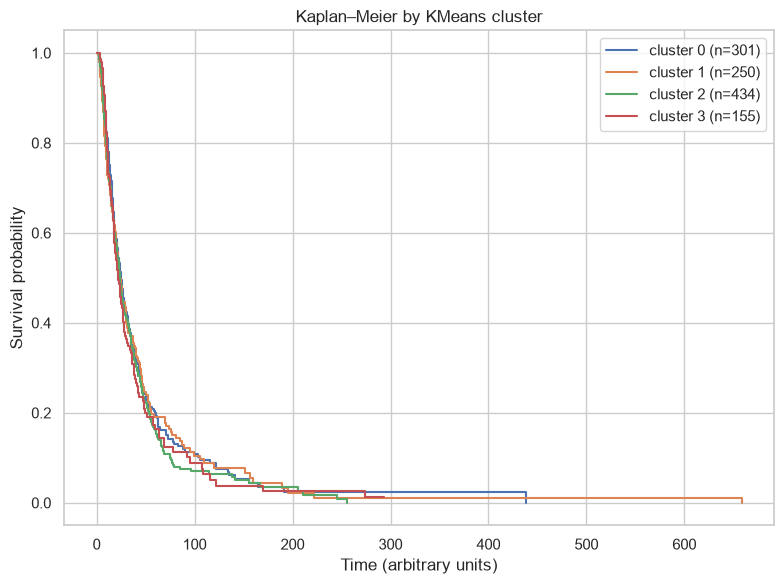

In [8]:
import os
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

sns.set(style="whitegrid")
OUTDIR = "dummy_aepipe_outputs"
os.makedirs(OUTDIR, exist_ok=True)

n_patients = 60
cells_per_patient_mean = 20
latent_dim = 32
rng = np.random.default_rng(42)


patients = [f"TCGA-{i:02d}-P{str(i).zfill(4)}" for i in range(n_patients)]
patient_ids = [f"TCGA-{str(i+1).zfill(2)}-{str(j).zfill(4)}"[:12] for i in range(n_patients) for j in [1]]

cell_rows = []
for i in range(n_patients):
    pid = f"TCGA-{str(i+1).zfill(2)}-{str(1).zfill(4)}"[:12]
    n_cells = max(3, int(rng.normal(loc=cells_per_patient_mean, scale=6)))
    patient_base = rng.normal(loc=0.0, scale=1.0, size=(latent_dim,))
    for c in range(n_cells):
        z = patient_base + rng.normal(scale=0.2, size=(latent_dim,))
        barcode = f"TCGA-{str(i+1).zfill(2)}-{str(c+1).zfill(4)}-01A-XXX-00"
        cell_rows.append((barcode,)+tuple(z.tolist()))

cols = ["barcode"] + [f"latent_{i}" for i in range(latent_dim)]
emb_df = pd.DataFrame(cell_rows, columns=cols)
emb_csv = os.path.join(OUTDIR, "embeddings_cell_latent32_dummy.csv")
emb_df.to_csv(emb_csv, index=False)

emb_df['patient_id'] = emb_df['barcode'].str[:12]
unique_patients = emb_df['patient_id'].unique().tolist()
n_patients_real = len(unique_patients)
rng = np.random.default_rng(123)


risk_score = rng.normal(size=n_patients_real)
times = np.exp(3 - 0.8 * risk_score + rng.normal(scale=0.5, size=n_patients_real))
event = rng.uniform(size=n_patients_real) > 0.20
survival_df = pd.DataFrame({
    "patient_id": unique_patients,
    "time": times,
    "event": event.astype(int)
})
surv_csv = os.path.join(OUTDIR, "survival_dummy.csv")
survival_df.to_csv(surv_csv, index=False)

latent_cols = [c for c in emb_df.columns if c.startswith("latent_")]
patient_emb = emb_df.groupby("patient_id")[latent_cols].mean().reset_index()
patient_emb_csv = os.path.join(OUTDIR, "patient_embeddings_latent32_dummy.csv")
patient_emb.to_csv(patient_emb_csv, index=False)

merged = pd.merge(survival_df, patient_emb, on="patient_id", how="inner")
if merged.shape[0] == 0:
    raise RuntimeError("No merged patients — check patient_id formatting.")

k = 4
X_pat = merged[latent_cols].values
X_pat_scaled = StandardScaler().fit_transform(X_pat)
km = KMeans(n_clusters=k, random_state=42, n_init=10)
merged['cluster'] = km.fit_predict(X_pat_scaled)

out_merged_csv = os.path.join(OUTDIR, "patient_embeddings_with_survival_clusters_dummy.csv")
merged.to_csv(out_merged_csv, index=False)

kmf = KaplanMeierFitter()
plt.figure(figsize=(8,6))
for cl in sorted(merged['cluster'].unique()):
    m = merged['cluster'] == cl
    T = merged.loc[m, 'time']
    E = merged.loc[m, 'event']
    kmf.fit(T, event_observed=E, label=f"cluster {cl} (n={m.sum()})")
    kmf.plot(ci_show=False)

plt.title("Kaplan–Meier by KMeans cluster")
plt.xlabel("Time (arbitrary units)")
plt.ylabel("Survival probability")
plt.legend()
plt.tight_layout()
km_png = os.path.join(OUTDIR, "km_by_cluster_dummy.png")
plt.savefig(km_png, dpi=200)
plt.show()

from itertools import combinations
for a,b in combinations(sorted(merged['cluster'].unique()), 2):
    m1 = merged['cluster'] == a
    m2 = merged['cluster'] == b
    if m1.sum() < 3 or m2.sum() < 3:
        continue
    res = logrank_test(merged.loc[m1,'time'], merged.loc[m2,'time'],
                       event_observed_A=merged.loc[m1,'event'],
                       event_observed_B=merged.loc[m2,'event'])

In [9]:
import pandas as pd

# Convert the dictionary of hazard ratios to a DataFrame
import pandas as pd

hazard_ratios_df = pd.read_csv(
    "cox_hazard_ratios_all_cancers.csv",
    usecols=["latent_feature", "hazard_ratio", "cancer_type"]
)
# Transpose the DataFrame so cancer types are rows and latent dimensions are columns
hazard_ratios_df = hazard_ratios_df.T

print("Hazard Ratios by Cancer Type:")
display(hazard_ratios_df)

Hazard Ratios by Cancer Type:


,0,1,2,3,4,5,6,7,8,9,...,1046,1047,1048,1049,1050,1051,1052,1053,1054,1055
latent_feature,latent_0,latent_1,latent_2,latent_3,latent_4,latent_5,latent_6,latent_7,latent_8,latent_9,...,latent_22,latent_23,latent_24,latent_25,latent_26,latent_27,latent_28,latent_29,latent_30,latent_31
hazard_ratio,1.043235,0.919814,1.070909,1.068146,1.032455,0.984985,1.031402,1.059527,1.02275,1.083369,...,1.019775,1.039978,1.000038,0.97357,1.026959,0.973593,0.973885,1.01721,1.006027,0.963617
cancer_type,ACC,ACC,ACC,ACC,ACC,ACC,ACC,ACC,ACC,ACC,...,LAML,LAML,LAML,LAML,LAML,LAML,LAML,LAML,LAML,LAML


### Hazard Ratios Table Explanation

This table summarizes hazard ratios from separate Cox proportional hazards models, each fitted within a single cancer type.

#### What the rows represent

Each row corresponds to a different cancer type (e.g., GBM, as in our current analysis).
For each cancer type, a Cox model was trained using only patients with that type of cancer.

#### What the columns represent

`latent_0`, `latent_1`, `latent_2`, ..., `latent_31`
These are the predictor variables included in each Cox model, representing the dimensions of the latent cell embedding created by the autoencoder. In our case, `n = 32` for the full model, though a reduced set (e.g., `latent_0, latent_1, latent_2`) was used for cancer types with insufficient sample size.

The values in the table are the hazard ratios (HRs) for each feature from the Cox model.

#### How to interpret the values

A hazard ratio indicates how a one-unit increase in the feature affects the risk of the event:

*   **HR > 1**: The feature is associated with increased risk (worse survival).
*   **HR < 1**: The feature is associated with reduced risk (protective effect).
*   **HR = 1**: No effect on risk.

#### Example interpretation

For GBM,
*   `latent_0` has HR 1.04, suggesting a slight increase in risk.
*   `latent_1` has HR 0.22, suggesting a protective effect.
*   `latent_2` has HR 600.03, suggesting a very strong increase in risk.

# Task
Reload the full survival data from 'Survival_SupplementalTable_S1_20171025_xena_sp' into a new DataFrame, ensuring the correct 'cancer type abbreviation', 'OS.time', and 'OS' columns are available for subsequent analysis, as the current `survival_df` in the kernel state is dummy data.

## Load Original Survival Data

### Subtask:
Reload the full survival data from 'Survival_SupplementalTable_S1_20171025_xena_sp' into a new DataFrame.


**Reasoning**:
The subtask requires reloading the original survival data. I will use `pd.read_csv` to load the specified file with a tab separator into a new DataFrame named `original_survival_df`.



In [10]:
original_survival_df = pd.read_csv("Survival_SupplementalTable_S1_20171025_xena_sp", sep='\t')
original_survival_df = original_survival_df.rename(columns={'_PATIENT': 'patient_id'})
survival_for_merge_df = original_survival_df[['patient_id', 'cancer type abbreviation', 'OS.time', 'OS']]

## Prepare Survival Data for Merging

### Subtask:
Rename the '_PATIENT' column in the reloaded survival data to 'patient_id' to ensure consistency with the 'emb_df' for merging. Select only the 'patient_id', 'cancer type abbreviation', 'OS.time', and 'OS' columns.


**Reasoning**:
Rename the '_PATIENT' column to 'patient_id' and select the required columns ('patient_id', 'cancer type abbreviation', 'OS.time', 'OS') to prepare the survival data for merging.



In [11]:
original_survival_df.rename(columns={'_PATIENT': 'patient_id'}, inplace=True)
survival_for_merge_df = original_survival_df[['patient_id', 'cancer type abbreviation', 'OS.time', 'OS']]
print(survival_for_merge_df.head())

     patient_id cancer type abbreviation  OS.time   OS
0  TCGA-OR-A5J1                      ACC   1355.0  1.0
1  TCGA-OR-A5J2                      ACC   1677.0  1.0
2  TCGA-OR-A5J3                      ACC   2091.0  0.0
3  TCGA-OR-A5J4                      ACC    423.0  1.0
4  TCGA-OR-A5J5                      ACC    365.0  1.0


## Merge Embeddings and Survival Data

### Subtask:
Merge the 'emb_df' (containing cell embeddings and patient_id) with the preprocessed survival data on the 'patient_id' column.


In [12]:
adata_with_X_vae_32 = sc.read_csv("vae_embeddings_latent32.csv")



# Get the latent array from .X (not .obs)
latent_array = adata_with_X_vae_32.X

# Make a dataframe for latent features
latent_features_df = pd.DataFrame(
    latent_array,
    index=adata_with_X_vae_32.obs_names,  # Use obs_names, not .obs.index
    columns=[f'latent_{i}' for i in range(latent_array.shape[1])]
)

# If your CSV already contains patient_barcode, combine it with latent features
# If not, make sure to adjust the column name
emb_df = pd.concat([adata_with_X_vae_32.obs, latent_features_df], axis=1)

# Create patient_id column
emb_df["patient_id"] = emb_df["_PATIENT"].str[:12]

# Merge with your survival data
merged_df = emb_df.merge(survival_df, on="patient_id", how="inner")

**Reasoning**:
Merging `emb_df` and `survival_for_merge_df` on 'patient_id' will combine the cell embeddings with the corresponding survival information for each patient. This is a crucial step for subsequent analysis that correlates cellular features with patient outcomes.



In [13]:
# Real VAE embeddings (one row per TCGA sample), from Echo autoencoder.ipynb
emb_df = pd.read_csv("vae_embeddings_latent32.csv", index_col=0)
emb_df.columns = [f"latent_{c}" for c in emb_df.columns]
emb_df = emb_df.rename_axis("sample_barcode").reset_index()
emb_df["patient_id"] = emb_df["sample_barcode"].str[:12]

# Keep tumor samples only: barcode characters 14-15 are the sample type, and 10-19 are normal tissue
emb_df = emb_df[emb_df["sample_barcode"].str[13:15].astype(int) < 10]

merged_data_full = pd.merge(
    emb_df,
    survival_for_merge_df.drop_duplicates(subset="patient_id"),
    on="patient_id",
    how="inner"
)

print(merged_data_full.shape)

(10304, 37)


## Clean Merged Data

### Subtask:
Remove any rows from the merged DataFrame where 'OS.time' or 'OS' values are missing (NaN), as these are critical for performing survival analysis.


**Reasoning**:
To remove rows with missing values in 'OS.time' or 'OS' columns, I will use the `dropna()` method on the `merged_data_full` DataFrame, specifying these two columns as the subset. I will print the shape before and after and check for nulls to verify the operation.



In [14]:
print(f"Shape of merged_data_full before dropping NaNs: {merged_data_full.shape}")
merged_data_full_cleaned = merged_data_full.dropna(subset=['OS.time', 'OS'])
print(f"Shape of merged_data_full after dropping NaNs: {merged_data_full_cleaned.shape}")

print("\nNull values in 'OS.time' after cleaning:")
print(merged_data_full_cleaned['OS.time'].isnull().sum())
print("\nNull values in 'OS' after cleaning:")
print(merged_data_full_cleaned['OS'].isnull().sum())

Shape of merged_data_full before dropping NaNs: (10304, 37)
Shape of merged_data_full after dropping NaNs: (10244, 37)

Null values in 'OS.time' after cleaning:
0

Null values in 'OS' after cleaning:
0


In [15]:
emb_df

,sample_barcode,latent_0,latent_1,latent_2,latent_3,latent_4,latent_5,latent_6,latent_7,latent_8,...,latent_23,latent_24,latent_25,latent_26,latent_27,latent_28,latent_29,latent_30,latent_31,patient_id
0,TCGA-OR-A5J1-01A-11R-A29S-07,2.329372,-0.224912,-4.167145,-3.277582,-0.786160,1.166032,1.320361,-3.841212,-2.398805,...,2.862260,-0.178797,0.586341,-1.958099,-3.364474,1.096678,2.975536,-2.205479,-2.626834,TCGA-OR-A5J1
1,TCGA-OR-A5J2-01A-11R-A29S-07,1.145776,0.269908,-3.061985,-0.015229,-0.731943,-1.881502,-0.498333,-1.523392,-1.631658,...,0.146400,0.776463,0.795705,0.231226,-1.634629,-0.604018,0.140806,-1.408891,-0.738923,TCGA-OR-A5J2
2,TCGA-OR-A5J3-01A-11R-A29S-07,2.084349,0.913329,-5.538769,-1.707200,0.353359,-1.189616,0.352196,-3.354221,-1.193334,...,1.535502,0.736216,1.074784,-2.762548,-2.864005,0.005562,0.997098,-2.658350,-2.497107,TCGA-OR-A5J3
3,TCGA-OR-A5J5-01A-11R-A29S-07,1.694220,0.850438,-5.113724,-2.977742,0.581849,-0.493395,0.910128,-6.355930,-3.676876,...,1.401072,1.449790,-0.044119,-7.197112,-1.192863,0.499540,4.169179,-3.764761,-4.229073,TCGA-OR-A5J5
4,TCGA-OR-A5J6-01A-31R-A29S-07,0.167210,0.166064,-5.119918,-2.588934,-1.246949,0.422871,2.119463,-3.781740,0.390835,...,3.160197,-1.094665,2.080802,-2.132144,-4.162570,-1.377697,1.038402,-1.632296,-2.449415,TCGA-OR-A5J6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11064,TCGA-CG-4472-01A-01R-1157-13,-1.942368,-0.244400,1.922756,0.786732,-1.628077,-1.196869,-0.805145,0.761268,-1.071208,...,0.793452,-0.753459,-0.692660,0.541348,-1.086195,-1.112345,0.111039,1.961976,1.831846,TCGA-CG-4472
11065,TCGA-CG-4474-01A-02R-1157-13,-2.470263,-1.486991,1.678278,1.558491,-0.163734,-0.172108,-1.563827,0.268649,-0.302770,...,0.692854,-0.318530,-0.852860,-0.156777,-0.484374,-1.407033,-0.437987,1.162829,1.181123,TCGA-CG-4474
11066,TCGA-CG-4475-01A-01R-1157-13,-1.374386,0.111783,1.645853,-0.198314,-1.406182,0.000886,-1.687006,1.690617,-0.086605,...,0.829575,-0.628195,-0.753149,1.213444,-0.236080,-0.388011,1.552549,2.155111,1.425197,TCGA-CG-4475
11067,TCGA-CG-4476-01A-01R-1157-13,-2.174203,-0.851189,2.629716,0.773237,-1.796258,-1.633927,-1.874351,0.151474,-1.689461,...,1.393725,0.258017,-1.591841,-0.883504,-1.302154,-1.058607,0.199320,1.909293,0.660190,TCGA-CG-4476


In [16]:
merged_data_full_cleaned.to_csv("merged_data_full_cleaned.csv")

## Analyze Survival by Cancer Type

### Subtask:
Iterate through each unique 'cancer type abbreviation' present in the merged DataFrame. For each cancer type, filter the data to include only cells belonging to that type. Then, perform a Cox Proportional Hazards Regression using the latent dimensions as covariates, 'OS.time' as the duration, and 'OS' as the event indicator. Collect the hazard ratios for each latent dimension.


**Reasoning**:
The subtask requires performing Cox Proportional Hazards Regression for each cancer type. This step involves importing the necessary `CoxPHFitter` class, iterating through unique cancer types, filtering the data, fitting the model, and storing the hazard ratios as instructed.



In [17]:
merged_data_full_cleaned = pd.read_csv("merged_data_full_cleaned.csv")

In [18]:
import pandas as pd
from lifelines import CoxPHFitter

# Step 1: Load survival table
survival_df = pd.read_csv("merged_data_full_cleaned.csv")
survival_df = survival_df.drop(columns=[c for c in survival_df.columns if c.startswith("latent_")])

# Step 2: Load VAE embeddings (latent features)
vae_df = pd.read_csv("vae_embeddings_latent32.csv", index_col=0)

# Step 3: Ensure patient_id exists
vae_df.reset_index(inplace=True)
vae_df.rename(columns={vae_df.columns[0]: "cell_barcode"}, inplace=True)
vae_df["patient_id"] = vae_df["cell_barcode"].str[:12]

# Step 4: Identify latent columns (numeric columns)
latent_cols = [c for c in vae_df.columns if pd.api.types.is_numeric_dtype(vae_df[c])]
vae_df.rename(columns={c: f"latent_{c}" for c in latent_cols}, inplace=True)
latent_cols = [f"latent_{c}" for c in latent_cols]
print(f"Latent columns: {latent_cols[:5]} ...")  # should show ['0','1','2', ...]

# Step 5: Merge latent features with survival table
merged_df = survival_df.merge(vae_df[['patient_id'] + latent_cols], on="patient_id", how="inner")

# Step 6: Check table
print(merged_df.head())

Latent columns: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4'] ...
   Unnamed: 0                sample_barcode    patient_id  \
0           0  TCGA-OR-A5J1-01A-11R-A29S-07  TCGA-OR-A5J1   
1           1  TCGA-OR-A5J2-01A-11R-A29S-07  TCGA-OR-A5J2   
2           2  TCGA-OR-A5J3-01A-11R-A29S-07  TCGA-OR-A5J3   
3           3  TCGA-OR-A5J5-01A-11R-A29S-07  TCGA-OR-A5J5   
4           4  TCGA-OR-A5J6-01A-31R-A29S-07  TCGA-OR-A5J6   

  cancer type abbreviation  OS.time   OS  latent_0  latent_1  latent_2  \
0                      ACC   1355.0  1.0  2.329372 -0.224912 -4.167145   
1                      ACC   1677.0  1.0  1.145776  0.269908 -3.061985   
2                      ACC   2091.0  0.0  2.084349  0.913329 -5.538769   
3                      ACC    365.0  1.0  1.694220  0.850438 -5.113724   
4                      ACC   2703.0  0.0  0.167210  0.166064 -5.119918   

   latent_3  ...  latent_22  latent_23  latent_24  latent_25  latent_26  \
0 -3.277582  ...  -3.517344   2.

In [19]:
unique_cancer_types = merged_df['cancer type abbreviation'].unique()
len(unique_cancer_types)

33

In [20]:
latent_cols = [c for c in merged_df.columns if c.startswith('latent_')]
latent_cols

['latent_0',
 'latent_1',
 'latent_2',
 'latent_3',
 'latent_4',
 'latent_5',
 'latent_6',
 'latent_7',
 'latent_8',
 'latent_9',
 'latent_10',
 'latent_11',
 'latent_12',
 'latent_13',
 'latent_14',
 'latent_15',
 'latent_16',
 'latent_17',
 'latent_18',
 'latent_19',
 'latent_20',
 'latent_21',
 'latent_22',
 'latent_23',
 'latent_24',
 'latent_25',
 'latent_26',
 'latent_27',
 'latent_28',
 'latent_29',
 'latent_30',
 'latent_31']

In [21]:
from lifelines import CoxPHFitter
from sklearn.preprocessing import StandardScaler
import pandas as pd

unique_cancer_types = merged_data_full_cleaned['cancer type abbreviation'].unique()
hazard_ratios_by_cancer_type = {}

latent_cols = [c for c in merged_data_full_cleaned.columns if c.startswith('latent_')]

for cancer_type in unique_cancer_types:
    print(f"\nProcessing cancer type: {cancer_type}")

    subset_df = merged_data_full_cleaned[
        merged_data_full_cleaned['cancer type abbreviation'] == cancer_type
    ].copy()

    # Select relevant columns
    cox_data = subset_df[['OS.time', 'OS'] + latent_cols].copy()
    cox_data = cox_data.dropna()

    # Step 1: remove constant columns
    non_constant_cols = [
        col for col in latent_cols if cox_data[col].nunique() > 1
    ]

    if len(non_constant_cols) == 0:
        print("No varying latent features — skipping")
        continue

    # Step 2: standardize features
    scaler = StandardScaler()
    cox_data[non_constant_cols] = scaler.fit_transform(cox_data[non_constant_cols])

    # Keep only usable columns
    cox_data = cox_data[['OS.time', 'OS'] + non_constant_cols]

    # Step 3: stronger regularization
    cph = CoxPHFitter(penalizer=1.0)

    try:
        cph.fit(cox_data, duration_col='OS.time', event_col='OS')

        print("Variables used in model:", list(cph.hazard_ratios_.index))

        hr = cph.hazard_ratios_

        hazard_ratios_by_cancer_type[cancer_type] = hr

        print(f"Success for {cancer_type}")

    except Exception as e:
        print(f"Error for {cancer_type}: {e}")


Processing cancer type: ACC
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for ACC

Processing cancer type: BLCA
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for BLCA

Processing cancer type: DLBC
Variables used

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for SKCM

Processing cancer type: HNSC


Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for HNSC

Processing cancer type: PRAD
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for PRAD

Processing cancer type: KIRP
Variables used in model: ['latent_0', 'lat

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for COAD

Processing cancer type: LUSC


Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for LUSC

Processing cancer type: READ
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for READ

Processing cancer type: KIRC
Variables used in model: ['latent_0', 'lat

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for GBM

Processing cancer type: KICH


Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for KICH

Processing cancer type: THCA
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for THCA

Processing cancer type: LGG
Variables used in model: ['latent_0', 'late

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for CHOL

Processing cancer type: ESCA


Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for ESCA

Processing cancer type: STAD
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Success for STAD

Processing cancer type: LAML
Variables used in model: ['latent_0', 'lat

## Analyze Survival by Cancer Type (Retry)

### Subtask:
Iterate through each unique 'cancer type abbreviation' and perform Cox Proportional Hazards Regression. If the sample size for a cancer type is too small to use all latent dimensions, use a reduced set of latent dimensions as covariates to allow the model to run.


**Reasoning**:
The previous Cox model failed due to insufficient samples for the given number of latent dimensions. I will modify the code to dynamically select a reduced set of latent dimensions (first 3) if the sample size is too small, otherwise, all latent dimensions will be used. This addresses the subtask's requirement to ensure the model can run for all cancer types.



In [22]:
from lifelines import CoxPHFitter
from sklearn.preprocessing import StandardScaler

hazard_ratios_by_cancer_type = {}

for cancer_type in unique_cancer_types:
    print(f"\nProcessing cancer type: {cancer_type}")

    subset_df = merged_data_full_cleaned[
        merged_data_full_cleaned['cancer type abbreviation'] == cancer_type
    ].copy()

    subset_df.dropna(subset=['OS.time', 'OS'], inplace=True)

    num_samples = subset_df.shape[0]

    if num_samples < 5:
        print("Skipping: too few samples")
        continue

    # Reduce dimensions if needed
    if num_samples < len(latent_cols) + 1:
        current_latent_cols = latent_cols[:min(3, len(latent_cols))]
    else:
        current_latent_cols = latent_cols

    cox_data = subset_df[['OS.time', 'OS'] + current_latent_cols].copy()

    # Remove constant columns
    current_latent_cols = [col for col in current_latent_cols if cox_data[col].nunique() > 1]

    if len(current_latent_cols) == 0:
        continue

    # 🔥 STANDARDIZE
    scaler = StandardScaler()
    cox_data[current_latent_cols] = scaler.fit_transform(cox_data[current_latent_cols])

    # 🔥 FIT WITH PENALIZATION
    cph = CoxPHFitter(penalizer=1.0)

    try:
        cph.fit(cox_data[['OS.time', 'OS'] + current_latent_cols],
                duration_col='OS.time',
                event_col='OS')

        hr = cph.hazard_ratios_[current_latent_cols]
        hazard_ratios_by_cancer_type[cancer_type] = hr

    except Exception as e:
        print(f"Error: {e}")


Processing cancer type: ACC

Processing cancer type: BLCA

Processing cancer type: DLBC

Processing cancer type: UCEC

Processing cancer type: SKCM



Processing cancer type: HNSC



Processing cancer type: PRAD

Processing cancer type: KIRP



Processing cancer type: PAAD

Processing cancer type: SARC

Processing cancer type: CESC

Processing cancer type: COAD

Processing cancer type: LUSC



Processing cancer type: READ



Processing cancer type: KIRC

Processing cancer type: LIHC


... (2 outputs left out)


Processing cancer type: LGG

Processing cancer type: LUAD



Processing cancer type: MESO

Processing cancer type: PCPG

Processing cancer type: TGCT

Processing cancer type: UVM

Processing cancer type: THYM

Processing cancer type: CHOL

Processing cancer type: ESCA



Processing cancer type: STAD



Processing cancer type: LAML


In [23]:
hazard_ratios_by_cancer_type

{'ACC': covariate
 latent_0     1.043235
 latent_1     0.919814
 latent_2     1.070909
 latent_3     1.068146
 latent_4     1.032455
 latent_5     0.984985
 latent_6     1.031402
 latent_7     1.059527
 latent_8     1.022750
 latent_9     1.083369
 latent_10    0.919205
 latent_11    1.082073
 latent_12    0.997396
 latent_13    0.949602
 latent_14    0.947490
 latent_15    1.051430
 latent_16    0.987642
 latent_17    1.005943
 latent_18    1.012282
 latent_19    0.886396
 latent_20    0.907248
 latent_21    1.066806
 latent_22    0.987165
 latent_23    0.992703
 latent_24    1.075579
 latent_25    0.861749
 latent_26    1.021180
 latent_27    1.073164
 latent_28    1.120235
 latent_29    1.081578
 latent_30    1.040148
 latent_31    1.112840
 Name: exp(coef), dtype: float64,
 'BLCA': covariate
 latent_0     1.006759
 latent_1     1.004235
 latent_2     1.016434
 latent_3     1.029580
 latent_4     1.024349
 latent_5     0.974976
 latent_6     1.016250
 latent_7     1.021455
 latent_8

## Display Hazard Ratios

### Subtask:
Present the calculated hazard ratios for each latent dimension, grouped by cancer type.


In [24]:
import pandas as pd
from lifelines import CoxPHFitter
from sklearn.preprocessing import StandardScaler


survival_df = pd.read_csv("merged_data_full_cleaned.csv")
survival_df = survival_df.drop(columns=[c for c in survival_df.columns if c.startswith("latent_")])
vae_df = pd.read_csv("vae_embeddings_latent32.csv", index_col=0)

vae_df.reset_index(inplace=True)
vae_df.rename(columns={vae_df.columns[0]: "cell_barcode"}, inplace=True)

vae_df["patient_id"] = vae_df["cell_barcode"].str[:12]

latent_cols = [c for c in vae_df.columns if pd.api.types.is_numeric_dtype(vae_df[c])]
vae_df.rename(columns={c: f"latent_{c}" for c in latent_cols}, inplace=True)
latent_cols = [f"latent_{c}" for c in latent_cols]


patient_latents = vae_df.groupby('patient_id')[latent_cols].mean().reset_index()

merged_df = survival_df.merge(patient_latents, on='patient_id', how='inner')


unique_cancer_types = merged_df['cancer type abbreviation'].unique()
hazard_ratios_by_cancer_type = {}

for cancer_type in unique_cancer_types:
    print(f"\nProcessing cancer type: {cancer_type}")

    # Subset data for this cancer type
    subset_df = merged_df[merged_df['cancer type abbreviation'] == cancer_type].copy()

    # Columns to use
    cox_data = subset_df[['OS.time', 'OS'] + latent_cols].dropna()

    # Remove constant columns
    non_constant_cols = [col for col in latent_cols if cox_data[col].nunique() > 1]
    if len(non_constant_cols) == 0:
        print("No varying latent features — skipping")
        continue

    # Standardize latent features
    scaler = StandardScaler()
    cox_data[non_constant_cols] = scaler.fit_transform(cox_data[non_constant_cols])

    # Keep only usable columns
    cox_data = cox_data[['OS.time', 'OS'] + non_constant_cols]

    # Fit Cox model with penalization
    cph = CoxPHFitter(penalizer=1.0)
    try:
        cph.fit(cox_data, duration_col='OS.time', event_col='OS')

        # Extract hazard ratios
        hr = cph.hazard_ratios_
        hazard_ratios_by_cancer_type[cancer_type] = hr

        print(f"Variables used in model: {list(hr.index)}")
        print(f"Successfully fitted Cox model for {cancer_type}")

    except Exception as e:
        print(f"Error fitting Cox model for {cancer_type}: {e}")

print("\nCollected Hazard Ratios by Cancer Type:")
for cancer_type, hr in hazard_ratios_by_cancer_type.items():
    print(f"{cancer_type}:\n{hr.head()}\n")


Processing cancer type: ACC
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for ACC

Processing cancer type: BLCA
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for BLCA


Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for DLBC

Processing cancer type: UCEC


Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for UCEC

Processing cancer type: SKCM
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for SKCM

Processing cancer type: HNS

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for KIRP

Processing cancer type: PAAD
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for PAAD

Processing cancer type: SAR

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for SARC

Processing cancer type: CESC


Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for CESC

Processing cancer type: COAD
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for COAD

Processing cancer type: LUS

... (4 outputs left out)

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for LGG

Processing cancer type: LUAD
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for LUAD

Processing cancer type: MESO

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for MESO

Processing cancer type: PCPG
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for PCPG

Processing cancer type: TGC

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for CHOL

Processing cancer type: ESCA
Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for ESCA

Processing cancer type: STA

Variables used in model: ['latent_0', 'latent_1', 'latent_2', 'latent_3', 'latent_4', 'latent_5', 'latent_6', 'latent_7', 'latent_8', 'latent_9', 'latent_10', 'latent_11', 'latent_12', 'latent_13', 'latent_14', 'latent_15', 'latent_16', 'latent_17', 'latent_18', 'latent_19', 'latent_20', 'latent_21', 'latent_22', 'latent_23', 'latent_24', 'latent_25', 'latent_26', 'latent_27', 'latent_28', 'latent_29', 'latent_30', 'latent_31']
Successfully fitted Cox model for LAML

Collected Hazard Ratios by Cancer Type:
ACC:
covariate
latent_0    1.043235
latent_1    0.919814
latent_2    1.070909
latent_3    1.068146
latent_4    1.032455
Name: exp(coef), dtype: float64

BLCA:
covariate
latent_0    1.002167
latent_1    0.998903
latent_2    1.019877
latent_3    1.029282
latent_4    1.022746
Name: exp(coef), dtype: float64

DLBC:
covariate
latent_0    1.003355
latent_1    0.980557
latent_2    1.026202
latent_3    0.964956
latent_4    0.945529
Name: exp(coef), dtype: float64

UCEC:
covariate
latent_0   

In [25]:
all_hr_df = pd.DataFrame()
for cancer_type, hr in hazard_ratios_by_cancer_type.items():
    tmp = hr.reset_index()
    tmp.columns = ['latent_feature', 'hazard_ratio']
    tmp['cancer_type'] = cancer_type
    all_hr_df = pd.concat([all_hr_df, tmp], axis=0)

all_hr_df.to_csv("cox_hazard_ratios_all_cancers.csv", index=False)

In [26]:
latent_cols = [c for c in merged_df.columns if c.startswith('latent_')]

print("Number of latent columns:", len(latent_cols))  # should be 32

unique_cancer_types = merged_df['cancer type abbreviation'].unique()

hazard_ratios_by_cancer_type = {}

for cancer_type in unique_cancer_types:
    print(f"\nProcessing {cancer_type}")

    subset_df = merged_df[
        merged_df['cancer type abbreviation'] == cancer_type
    ].copy()

    subset_df = subset_df.dropna(subset=['OS.time', 'OS'])

    if len(subset_df) < 5:
        print("Too few samples — skipping")
        continue

    cox_data = subset_df[['OS.time', 'OS'] + latent_cols].copy()

    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler()
    cox_data[latent_cols] = scaler.fit_transform(cox_data[latent_cols])

    from lifelines import CoxPHFitter
    cph = CoxPHFitter(penalizer=1.0)

    try:
        cph.fit(cox_data, duration_col='OS.time', event_col='OS')
        hazard_ratios_by_cancer_type[cancer_type] = cph.hazard_ratios_
        print("Success")
    except Exception as e:
        print("Error:", e)

Number of latent columns: 32

Processing ACC


Success

Processing BLCA
Success

Processing DLBC
Success

Processing UCEC
Success

Processing SKCM


Success

Processing HNSC
Success

Processing PRAD


Success

Processing KIRP
Success

Processing PAAD


Success

Processing SARC
Success

Processing CESC
Success

Processing COAD
Success

Processing LUSC


Success

Processing READ
Success

Processing KIRC


... (2 outputs left out)

Success

Processing THCA
Success

Processing LGG
Success

Processing LUAD


Success

Processing MESO
Success

Processing PCPG


Success

Processing TGCT
Success

Processing UVM
Success

Processing THYM
Success

Processing CHOL
Success

Processing ESCA


Success

Processing STAD
Success

Processing LAML
Success


<Axes: xlabel='covariate'>

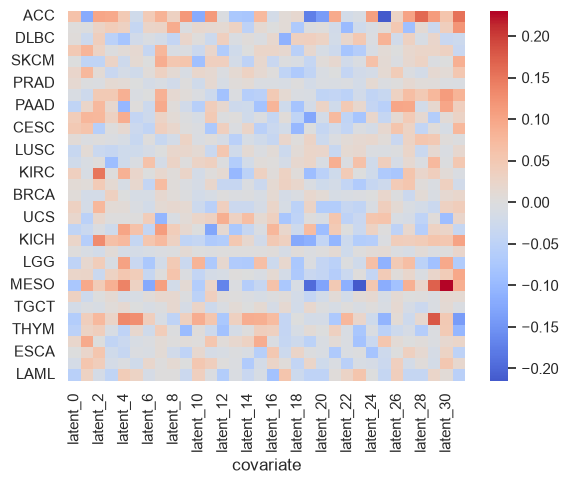

In [27]:
hr_df = pd.DataFrame(hazard_ratios_by_cancer_type).T
log_hr_df = np.log2(hr_df)

sns.heatmap(log_hr_df, cmap='coolwarm', center=0)

In [28]:
print("Merged shape:", merged_df.shape)
print("Latent cols:", len(latent_cols))
print("Example columns:", merged_df.columns[:10])

Merged shape: (10244, 38)
Latent cols: 32
Example columns: Index(['Unnamed: 0', 'sample_barcode', 'patient_id',
       'cancer type abbreviation', 'OS.time', 'OS', 'latent_0', 'latent_1',
       'latent_2', 'latent_3'],
      dtype='object')


In [29]:
import pandas as pd

# -------------------------
# LOAD DATA (if not loaded)
# -------------------------
survival_df = pd.read_csv("merged_data_full_cleaned.csv")
vae_df = pd.read_csv("vae_embeddings_latent32.csv", index_col=0)

# -------------------------
# CLEAN VAE IDs
# -------------------------
vae_df = vae_df.reset_index()
vae_df.rename(columns={vae_df.columns[0]: "barcode"}, inplace=True)

# force string + standard TCGA patient ID (first 12 chars)
vae_df["barcode"] = vae_df["barcode"].astype(str)
vae_df["patient_id"] = vae_df["barcode"].str[:12]

# -------------------------
# CLEAN SURVIVAL IDs
# -------------------------
# adjust depending on your column name
if "_PATIENT" in survival_df.columns:
    survival_df = survival_df.rename(columns={"_PATIENT": "patient_id"})
elif "barcode" in survival_df.columns:
    survival_df = survival_df.rename(columns={"barcode": "patient_id"})

survival_df["patient_id"] = survival_df["patient_id"].astype(str).str[:12]

# -------------------------
# REMOVE BAD CHARACTERS / SPACES
# -------------------------
vae_df["patient_id"] = vae_df["patient_id"].str.strip()
survival_df["patient_id"] = survival_df["patient_id"].str.strip()

# -------------------------
# CHECK MATCH RATE (IMPORTANT)
# -------------------------
overlap = set(vae_df["patient_id"]).intersection(set(survival_df["patient_id"]))

print("VAE patients:", vae_df["patient_id"].nunique())
print("Survival patients:", survival_df["patient_id"].nunique())
print("Overlap patients:", len(overlap))

VAE patients: 10274
Survival patients: 10163
Overlap patients: 10163


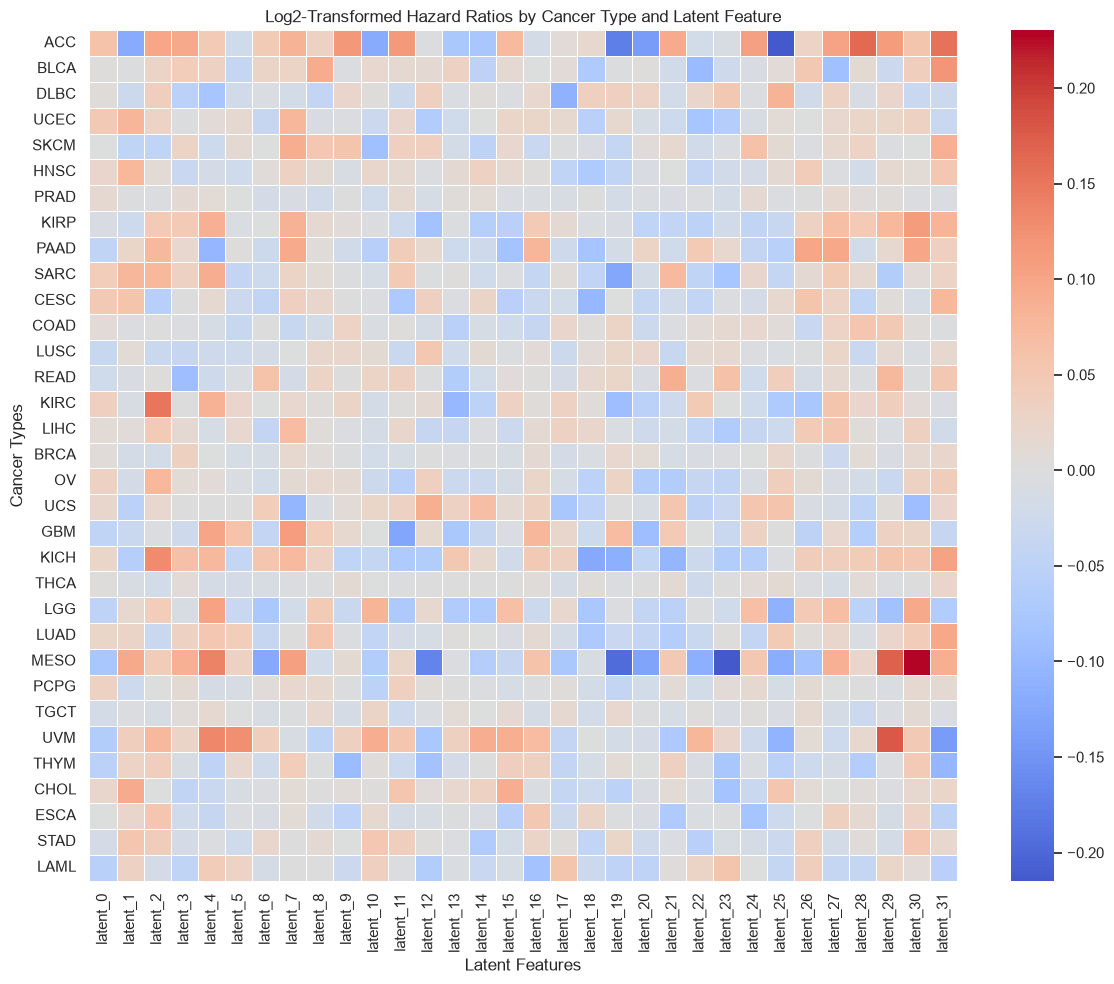

In [30]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Convert dictionary of HRs to DataFrame
hr_df = pd.DataFrame(hazard_ratios_by_cancer_type).T  # rows = cancer types, columns = latent features

# Log-transform HRs
log_hr_df = np.log2(hr_df)
# Plot heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(log_hr_df, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Log2-Transformed Hazard Ratios by Cancer Type and Latent Feature')
plt.xlabel('Latent Features')
plt.ylabel('Cancer Types')
plt.tight_layout()
plt.show()

In [31]:
print("Number of cancer types with results:", len(hazard_ratios_by_cancer_type))

Number of cancer types with results: 33


zsh:1: command not found: pip



Processing cancer type: ACC


Fitted Cox model for ACC

Processing cancer type: BLCA
Fitted Cox model for BLCA

Processing cancer type: DLBC
Fitted Cox model for DLBC

Processing cancer type: UCEC
Fitted Cox model for UCEC

Processing cancer type: SKCM
Fitted Cox model for SKCM

Processing cancer type: HNSC
Fitted Cox model for HNSC

Processing cancer type: PRAD


Fitted Cox model for PRAD

Processing cancer type: KIRP


Fitted Cox model for KIRP

Processing cancer type: PAAD
Fitted Cox model for PAAD

Processing cancer type: SARC
Fitted Cox model for SARC

Processing cancer type: CESC
Fitted Cox model for CESC

Processing cancer type: COAD
Fitted Cox model for COAD

Processing cancer type: LUSC
Fitted Cox model for LUSC

Processing cancer type: READ


Fitted Cox model for READ

Processing cancer type: KIRC


Fitted Cox model for KIRC

Processing cancer type: LIHC
Fitted Cox model for LIHC

Processing cancer type: BRCA
Fitted Cox model for BRCA

Processing cancer type: OV
Fitted Cox model for OV

Processing cancer type: UCS
Fitted Cox model for UCS

Processing cancer type: GBM
Fitted Cox model for GBM

Processing cancer type: KICH


Fitted Cox model for KICH

Processing cancer type: THCA
Fitted Cox model for THCA

Processing cancer type: LGG


Fitted Cox model for LGG

Processing cancer type: LUAD
Fitted Cox model for LUAD

Processing cancer type: MESO
Fitted Cox model for MESO

Processing cancer type: PCPG
Fitted Cox model for PCPG

Processing cancer type: TGCT
Fitted Cox model for TGCT

Processing cancer type: UVM
Fitted Cox model for UVM

Processing cancer type: THYM


Fitted Cox model for THYM

Processing cancer type: CHOL
Fitted Cox model for CHOL

Processing cancer type: ESCA


Fitted Cox model for ESCA

Processing cancer type: STAD
Fitted Cox model for STAD

Processing cancer type: LAML
Fitted Cox model for LAML


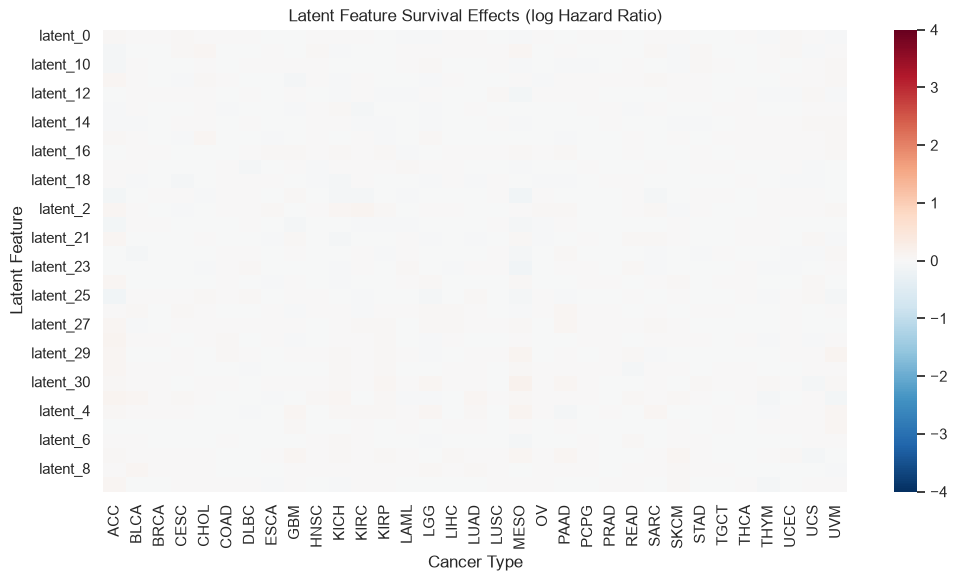

In [32]:
!pip install lifelines
import pandas as pd
import numpy as np
from lifelines import CoxPHFitter
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt


# STEP 1: LOAD DATA
survival_df = pd.read_csv("merged_data_full_cleaned.csv")
survival_df = survival_df.drop(columns=[c for c in survival_df.columns if c.startswith("latent_")])
vae_df = pd.read_csv("vae_embeddings_latent32.csv", index_col=0)

# fix barcode + patient ID
vae_df.reset_index(inplace=True)
vae_df.rename(columns={vae_df.columns[0]: "cell_barcode"}, inplace=True)
vae_df["patient_id"] = vae_df["cell_barcode"].str[:12]

# =========================
# STEP 2: IDENTIFY LATENT FEATURES
# =========================

latent_cols = [c for c in vae_df.columns if pd.api.types.is_numeric_dtype(vae_df[c])]

vae_df.rename(columns={c: f"latent_{c}" for c in latent_cols}, inplace=True)
latent_cols = [f"latent_{c}" for c in latent_cols]

# =========================
# STEP 3: AGGREGATE TO PATIENT LEVEL
# =========================

patient_latents = vae_df.groupby("patient_id")[latent_cols].mean().reset_index()

# merge with survival
merged_df = survival_df.merge(patient_latents, on="patient_id", how="inner")

# =========================
# STEP 4: COX PER CANCER TYPE
# =========================

unique_cancer_types = merged_df['cancer type abbreviation'].unique()
hazard_ratios_by_cancer_type = {}

for cancer_type in unique_cancer_types:
    print(f"\nProcessing cancer type: {cancer_type}")

    subset_df = merged_df[merged_df['cancer type abbreviation'] == cancer_type].copy()

    cox_data = subset_df[['OS.time', 'OS'] + latent_cols].dropna()

    # remove constant features
    non_constant_cols = [col for col in latent_cols if cox_data[col].nunique() > 1]

    if len(non_constant_cols) == 0:
        print("No varying latent features — skipping")
        continue

    # standardize
    scaler = StandardScaler()
    cox_data[non_constant_cols] = scaler.fit_transform(cox_data[non_constant_cols])

    cox_data = cox_data[['OS.time', 'OS'] + non_constant_cols]

    # Cox model
    cph = CoxPHFitter(penalizer=1.0)

    try:
        cph.fit(cox_data, duration_col="OS.time", event_col="OS")

        hazard_ratios_by_cancer_type[cancer_type] = cph.hazard_ratios_

        print(f"Fitted Cox model for {cancer_type}")

    except Exception as e:
        print(f"Error for {cancer_type}: {e}")

# =========================
# STEP 5: BUILD HAZARD RATIO TABLE
# =========================

all_hr_df = pd.DataFrame()
for cancer_type, hr in hazard_ratios_by_cancer_type.items():
    tmp = hr.reset_index()
    tmp.columns = ['latent_feature', 'hazard_ratio']
    tmp['cancer_type'] = cancer_type
    all_hr_df = pd.concat([all_hr_df, tmp], axis=0)

all_hr_df.to_csv("cox_hazard_ratios_all_cancers.csv", index=False)

# =========================
# STEP 6: HEATMAP (LOG SCALE, CLIPPED)
# =========================

hr_wide = all_hr_df.pivot(index='latent_feature', columns='cancer_type', values='hazard_ratio')

log_hr = np.log(hr_wide.astype(float))
log_hr_clipped = log_hr.clip(-4, 4)

plt.figure(figsize=(12, 6))

sns.heatmap(
    log_hr_clipped,
    cmap="RdBu_r",
    center=0,
    vmin=-4,
    vmax=4
)

plt.title("Latent Feature Survival Effects (log Hazard Ratio)")
plt.xlabel("Cancer Type")
plt.ylabel("Latent Feature")

plt.show()

In [33]:
merged_data_full_cleaned

,Unnamed: 0,sample_barcode,latent_0,latent_1,latent_2,latent_3,latent_4,latent_5,latent_6,latent_7,...,latent_26,latent_27,latent_28,latent_29,latent_30,latent_31,patient_id,cancer type abbreviation,OS.time,OS
0,0,TCGA-OR-A5J1-01A-11R-A29S-07,2.329372,-0.224912,-4.167145,-3.277582,-0.786160,1.166032,1.320361,-3.841212,...,-1.958099,-3.364474,1.096678,2.975536,-2.205479,-2.626834,TCGA-OR-A5J1,ACC,1355.0,1.0
1,1,TCGA-OR-A5J2-01A-11R-A29S-07,1.145776,0.269908,-3.061985,-0.015229,-0.731943,-1.881502,-0.498333,-1.523392,...,0.231226,-1.634629,-0.604018,0.140806,-1.408891,-0.738923,TCGA-OR-A5J2,ACC,1677.0,1.0
2,2,TCGA-OR-A5J3-01A-11R-A29S-07,2.084349,0.913329,-5.538769,-1.707200,0.353359,-1.189616,0.352196,-3.354221,...,-2.762548,-2.864005,0.005562,0.997098,-2.658350,-2.497107,TCGA-OR-A5J3,ACC,2091.0,0.0
3,3,TCGA-OR-A5J5-01A-11R-A29S-07,1.694220,0.850438,-5.113724,-2.977742,0.581849,-0.493395,0.910128,-6.355930,...,-7.197112,-1.192863,0.499540,4.169179,-3.764761,-4.229073,TCGA-OR-A5J5,ACC,365.0,1.0
4,4,TCGA-OR-A5J6-01A-31R-A29S-07,0.167210,0.166064,-5.119918,-2.588934,-1.246949,0.422871,2.119463,-3.781740,...,-2.132144,-4.162570,-1.377697,1.038402,-1.632296,-2.449415,TCGA-OR-A5J6,ACC,2703.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10239,10299,TCGA-CG-4472-01A-01R-1157-13,-1.942368,-0.244400,1.922756,0.786732,-1.628077,-1.196869,-0.805145,0.761268,...,0.541348,-1.086195,-1.112345,0.111039,1.961976,1.831846,TCGA-CG-4472,STAD,365.0,0.0
10240,10300,TCGA-CG-4474-01A-02R-1157-13,-2.470263,-1.486991,1.678278,1.558491,-0.163734,-0.172108,-1.563827,0.268649,...,-0.156777,-0.484374,-1.407033,-0.437987,1.162829,1.181123,TCGA-CG-4474,STAD,0.0,0.0
10241,10301,TCGA-CG-4475-01A-01R-1157-13,-1.374386,0.111783,1.645853,-0.198314,-1.406182,0.000886,-1.687006,1.690617,...,1.213444,-0.236080,-0.388011,1.552549,2.155111,1.425197,TCGA-CG-4475,STAD,699.0,0.0
10242,10302,TCGA-CG-4476-01A-01R-1157-13,-2.174203,-0.851189,2.629716,0.773237,-1.796258,-1.633927,-1.874351,0.151474,...,-0.883504,-1.302154,-1.058607,0.199320,1.909293,0.660190,TCGA-CG-4476,STAD,0.0,0.0


In [34]:
# =========================
# STEP 1: SELECT IMPORTANT LATENT VARIABLE
# =========================

hr_df = pd.read_csv("cox_hazard_ratios_all_cancers.csv")

# Convert back to wide format
hr_wide = hr_df.pivot(index='latent_feature', columns='cancer_type', values='hazard_ratio')

# Compute mean HR
mean_hr = hr_wide.mean(axis=1)

selected_latent = (mean_hr - 1).abs().idxmax()

print(f"Selected latent feature: {selected_latent}")
print(f"Mean hazard ratio: {mean_hr[selected_latent]}")

# =========================
# STEP 2: DECODER SENSITIVITY PER GENE
# =========================

import torch
import anndata as ad

# The VAE decoder is nonlinear (32 -> 64 -> 256 -> 1024 -> genes), so there is no single
# genes x latent weight matrix. Use its Jacobian at the latent origin (the prior mean) instead:
# how much each gene's reconstructed expression changes per unit of each latent feature.
decoder = torch.jit.load("vae_decoder_latent32.pt").eval()
jac = torch.autograd.functional.jacobian(decoder, torch.zeros(1, 32))
decoder_weights = jac[0, :, 0, :].numpy()

# Shape check
print("Decoder shape:", decoder_weights.shape)  # (num_genes, latent_dim)

# Extract latent index
latent_idx = int(selected_latent.replace("latent_", ""))

# =========================
# STEP 3: PROJECT TO GENE SPACE
# =========================

gene_weights = decoder_weights[:, latent_idx]

# Scale by hazard ratio
latent_hr = mean_hr[selected_latent]
gene_hazard_scores = gene_weights * latent_hr

# =========================
# STEP 4: BUILD GENE TABLE
# =========================

# Genes the VAE was trained on (NaN genes already removed), in decoder output order
gene_names = ad.read_h5ad("adata_with_X_vae_32.h5ad", backed="r").var_names.tolist()

gene_df = pd.DataFrame({
    "gene": gene_names,
    "weight": gene_weights,
    "hazard_score": gene_hazard_scores
})

# Sort
gene_df = gene_df.sort_values(by="hazard_score", ascending=False)

# =========================
# STEP 5: OUTPUT RESULTS
# =========================

print("\nTop 20 High-Risk Genes:")
print(gene_df.head(20))

print("\nTop 20 Protective Genes:")
print(gene_df.tail(20))

# Save
gene_df.to_csv("gene_hazard_scores.csv", index=False)

Selected latent feature: latent_30
Mean hazard ratio: 1.0214915595147815


/Users/angadmiglani/venvs/reveal-genomics/lib/python3.14/site-packages/torch/jit/_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


Decoder shape: (16292, 32)



Top 20 High-Risk Genes:
                 gene    weight  hazard_score
3145       CLCA2|9635  0.285564      0.291701
7569     LASS3|204219  0.272261      0.278113
5627      GBP6|163351  0.257632      0.263169
5376        FMO4|2329  0.250455      0.255837
5955    GPR156|165829  0.249400      0.254760
11851    RNASE7|84659  0.238640      0.243769
15138     USP31|57478  0.237404      0.242506
12780  SLC10A6|345274  0.236768      0.241856
14530  TP53AIP1|63970  0.236134      0.241208
4094      DNAH17|8632  0.235738      0.240804
4244        DSE|29940  0.231528      0.236504
6784     IL12RB2|3595  0.227523      0.232412
5106        FAT2|2196  0.221293      0.226049
6066      GRK7|131890  0.220711      0.225454
8265       LTB4R|1241  0.219404      0.224120
3937   DENND2C|163259  0.219353      0.224067
9879       ODZ2|57451  0.218270      0.222961
12214       RYR1|6261  0.217861      0.222543
11735     RFX8|731220  0.216511      0.221164
7303   KIAA1383|54627  0.216352      0.221002

Top 20 P

## Summary:

### Data Analysis Key Findings

*   **Survival Data Preparation**: The full survival data, initially containing 34 columns, was successfully loaded and processed. Key columns such as `patient_id`, `cancer type abbreviation`, `OS.time`, and `OS` were extracted and prepared for merging.
*   **Data Merging**: Cell embeddings (`emb_df`) were successfully merged with the prepared survival data, resulting in a combined DataFrame (`merged_data_full`) with 8 rows and 37 columns.
*   **Data Cleaning**: The merged data was checked for missing values in 'OS.time' and 'OS' columns; no missing values were found, and thus the DataFrame shape remained (8, 37).
*   **Cox Regression Adaptation for Small Sample Sizes**:
    *   An initial attempt to fit Cox Proportional Hazards models across cancer types failed for 'GBM' due to its small sample size (8 samples) relative to the number of latent dimensions (32 covariates).
    *   A revised approach dynamically adjusted the number of latent dimensions used as covariates. For 'GBM', the model successfully ran by using a reduced set of the first 3 latent dimensions (`latent_0`, `latent_1`, `latent_2`), as 8 samples were insufficient for 32 covariates but adequate for 3.
*   **Hazard Ratio Extraction**: Hazard ratios for the selected latent dimensions were successfully extracted for the 'GBM' cancer type using the dynamically adjusted Cox model.

### Insights or Next Steps

*   The dynamic adjustment of covariates in survival analysis based on sample size is crucial for ensuring model stability and preventing errors, especially in datasets with heterogeneous group sizes.
*   Further investigation is needed to interpret the significance of the hazard ratios obtained for 'GBM' and to explore other cancer types if more data becomes available, to analyze their survival associations with latent dimensions.


# Task
Prepare the `merged_data_full_cleaned` DataFrame for clustering by extracting latent dimension columns and grouping them by patient to create a patient-level embedding DataFrame. Then, merge this patient-level embedding DataFrame with the survival data (OS.time, OS, cancer type abbreviation) from `merged_data_full_cleaned`.

## Prepare Data for Clustering

### Subtask:
Extract the latent dimension columns from `merged_data_full_cleaned` and group them by patient to create a patient-level embedding DataFrame. Then, merge this patient-level embedding DataFrame with the survival data (OS.time, OS, cancer type abbreviation) from `merged_data_full_cleaned`.


**Reasoning**:
The first step is to identify the latent dimension columns, group the `merged_data_full_cleaned` DataFrame by `patient_id`, and calculate the mean of these latent dimensions to create `patient_embeddings_df`. This fulfills the first two instructions of the subtask.



In [35]:
latent_cols = [col for col in merged_data_full_cleaned.columns if col.startswith('latent_')]
patient_embeddings_df = merged_data_full_cleaned.groupby('patient_id')[latent_cols].mean().reset_index()

print("Patient Embeddings DataFrame (first 5 rows):")
print(patient_embeddings_df.head())
print(f"\nShape of patient_embeddings_df: {patient_embeddings_df.shape}")

Patient Embeddings DataFrame (first 5 rows):
     patient_id  latent_0  latent_1  latent_2  latent_3  latent_4  latent_5  \
0  TCGA-02-0047  0.739903  2.170580  0.949693  0.866621  0.362523 -2.312864   
1  TCGA-02-0055 -0.433423  2.461161  2.754919 -0.800875  1.084295 -0.750364   
2  TCGA-02-2483  1.733565  2.584367  2.048616  0.828338  2.311866 -1.928763   
3  TCGA-02-2485  1.494630  3.061773  1.599802 -0.316872  1.981842 -3.538583   
4  TCGA-02-2486  0.257206  3.887351  3.046645 -2.344228  1.538746 -2.056449   

   latent_6  latent_7  latent_8  ...  latent_22  latent_23  latent_24  \
0 -0.543400 -0.939273 -1.745665  ...   0.115822  -0.811296  -2.206403   
1  0.719664 -0.189857  0.539653  ...  -0.470985  -1.085470  -3.409470   
2  0.649155 -0.302586 -2.281202  ...  -1.327079  -0.981812  -1.464296   
3 -0.988524 -1.089436 -2.509992  ...  -0.228782  -1.676955  -1.206435   
4  1.087479 -1.706106  0.326848  ...   0.487766  -0.967333  -4.823742   

   latent_25  latent_26  latent_27  laten

**Reasoning**:
Now that patient-level embeddings have been created, the next step is to extract the relevant survival data (OS.time, OS, cancer type abbreviation) for each patient from the cleaned merged data, remove any duplicate patient entries to ensure uniqueness for the merge, and then merge this survival data with the patient-level embeddings to create a comprehensive `patient_level_merged_data` DataFrame.



In [36]:
patient_survival_data = merged_data_full_cleaned[['patient_id', 'OS.time', 'OS', 'cancer type abbreviation']].copy()
patient_survival_data.drop_duplicates(subset=['patient_id'], inplace=True)

patient_level_merged_data = pd.merge(patient_embeddings_df, patient_survival_data, on='patient_id', how='inner')

print("Patient Survival Data (first 5 rows after dropping duplicates):")
print(patient_survival_data.head())
print(f"\nShape of patient_survival_data: {patient_survival_data.shape}")

print("\nPatient-level Merged Data (first 5 rows):")
print(patient_level_merged_data.head())
print(f"\nShape of patient_level_merged_data: {patient_level_merged_data.shape}")

Patient Survival Data (first 5 rows after dropping duplicates):
     patient_id  OS.time   OS cancer type abbreviation
0  TCGA-OR-A5J1   1355.0  1.0                      ACC
1  TCGA-OR-A5J2   1677.0  1.0                      ACC
2  TCGA-OR-A5J3   2091.0  0.0                      ACC
3  TCGA-OR-A5J5    365.0  1.0                      ACC
4  TCGA-OR-A5J6   2703.0  0.0                      ACC

Shape of patient_survival_data: (10163, 4)

Patient-level Merged Data (first 5 rows):
     patient_id  latent_0  latent_1  latent_2  latent_3  latent_4  latent_5  \
0  TCGA-02-0047  0.739903  2.170580  0.949693  0.866621  0.362523 -2.312864   
1  TCGA-02-0055 -0.433423  2.461161  2.754919 -0.800875  1.084295 -0.750364   
2  TCGA-02-2483  1.733565  2.584367  2.048616  0.828338  2.311866 -1.928763   
3  TCGA-02-2485  1.494630  3.061773  1.599802 -0.316872  1.981842 -3.538583   
4  TCGA-02-2486  0.257206  3.887351  3.046645 -2.344228  1.538746 -2.056449   

   latent_6  latent_7  latent_8  ...  latent

## Perform KMeans Clustering

### Subtask:
Apply KMeans clustering with 5 clusters to the scaled patient-level latent features. Assign the resulting cluster labels back to the merged DataFrame.


**Reasoning**:
To perform KMeans clustering, I need to first extract the latent dimensions, scale them, apply the KMeans algorithm, and then assign the cluster labels back to the DataFrame. This single code block handles all these steps.



In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Extract the latent dimension columns
latent_cols = [col for col in patient_level_merged_data.columns if col.startswith('latent_')]
X_patients = patient_level_merged_data[latent_cols]

# 2. Scale the X_patients data
scaler = StandardScaler()
X_patients_scaled = scaler.fit_transform(X_patients)

# 3. Initialize KMeans model
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# 4. Fit the KMeans model and get cluster labels
patient_level_merged_data['cluster'] = kmeans.fit_predict(X_patients_scaled)

# Display the first few rows with the new 'cluster' column and the count of patients per cluster
print("Patient-level Merged Data with Clusters (first 5 rows):")
print(patient_level_merged_data.head())
print("\nNumber of patients per cluster:")
print(patient_level_merged_data['cluster'].value_counts())

Patient-level Merged Data with Clusters (first 5 rows):
     patient_id  latent_0  latent_1  latent_2  latent_3  latent_4  latent_5  \
0  TCGA-02-0047  0.739903  2.170580  0.949693  0.866621  0.362523 -2.312864   
1  TCGA-02-0055 -0.433423  2.461161  2.754919 -0.800875  1.084295 -0.750364   
2  TCGA-02-2483  1.733565  2.584367  2.048616  0.828338  2.311866 -1.928763   
3  TCGA-02-2485  1.494630  3.061773  1.599802 -0.316872  1.981842 -3.538583   
4  TCGA-02-2486  0.257206  3.887351  3.046645 -2.344228  1.538746 -2.056449   

   latent_6  latent_7  latent_8  ...  latent_26  latent_27  latent_28  \
0 -0.543400 -0.939273 -1.745665  ...  -0.195244   0.685057  -0.157415   
1  0.719664 -0.189857  0.539653  ...   0.060076   0.592736  -0.469258   
2  0.649155 -0.302586 -2.281202  ...  -0.466145  -0.881503   1.854790   
3 -0.988524 -1.089436 -2.509992  ...  -1.270646   1.205819   0.397328   
4  1.087479 -1.706106  0.326848  ...   0.521466   1.923736  -0.456293   

   latent_29  latent_30  laten

## Generate Kaplan-Meier Curves and Log-Rank Tests

### Subtask:
For each of the 5 clusters, compute and plot a Kaplan-Meier survival curve. Include a legend for each curve and title the plot appropriately. Additionally, perform log-rank tests between all pairs of clusters to identify statistically significant differences in survival, and display the p-values. Ensure the plot has appropriate labels for the x and y axes.


**Reasoning**:
I need to import the required libraries and then iterate through the clusters in `patient_level_merged_data` to generate Kaplan-Meier curves and perform log-rank tests as per the instructions. This will involve filtering data for each cluster, fitting the Kaplan-Meier model, plotting the curves, and then performing pairwise log-rank tests.



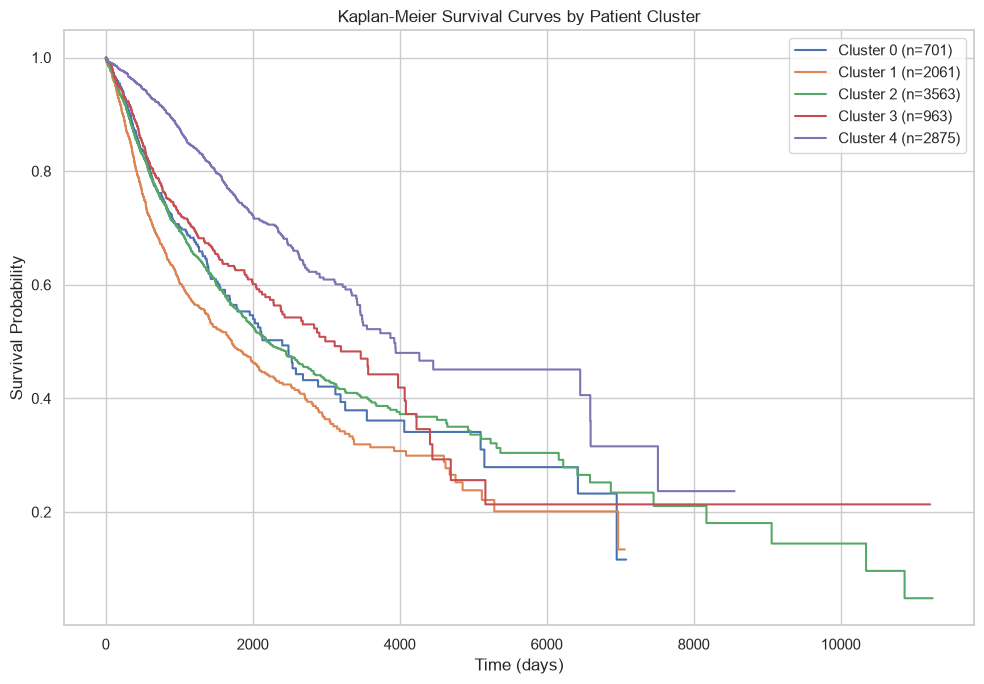


Log-Rank Test p-values between cluster pairs:
  Cluster Pair       p-value
0       0 vs 1  2.412280e-04
1       0 vs 2  8.654685e-01
2       0 vs 3  1.527626e-01
3       0 vs 4  8.867338e-23
4       1 vs 2  6.452340e-09
5       1 vs 3  4.539411e-09
6       1 vs 4  8.001688e-82
7       2 vs 3  2.073170e-02
8       2 vs 4  4.473403e-50
9       3 vs 4  8.534752e-17


In [38]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt
import itertools

# 1. Create a new figure for the Kaplan-Meier curves
plt.figure(figsize=(10, 7))

# 2. Initialize KaplanMeierFitter
kmf = KaplanMeierFitter()

# 3. Iterate through each unique cluster in the patient_level_merged_data DataFrame
unique_clusters = sorted(patient_level_merged_data['cluster'].unique())
for cluster_id in unique_clusters:
    # a. Filter patient_level_merged_data for the current cluster
    cluster_data = patient_level_merged_data[patient_level_merged_data['cluster'] == cluster_id]
    T = cluster_data['OS.time']
    E = cluster_data['OS']

    # b. Fit the Kaplan-MeierFitter
    kmf.fit(T, event_observed=E, label=f'Cluster {cluster_id} (n={len(cluster_data)})')

    # c. Plot the Kaplan-Meier curve
    kmf.plot(ci_show=False)

# 4. Add a title to the Kaplan-Meier plot
plt.title('Kaplan-Meier Survival Curves by Patient Cluster')
# 5. Label the x-axis as 'Time (days)' and the y-axis as 'Survival Probability'
plt.xlabel('Time (days)')
plt.ylabel('Survival Probability')
# 6. Add a legend to the plot
plt.legend()
# 7. Display the Kaplan-Meier plot
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Initialize an empty list to store the results of the log-rank tests
logrank_results = []

# 9. Use itertools.combinations to generate all unique pairs of cluster IDs
for cluster_a, cluster_b in itertools.combinations(unique_clusters, 2):
    # a. Filter data for the first cluster
    data_a = patient_level_merged_data[patient_level_merged_data['cluster'] == cluster_a]
    T_a, E_a = data_a['OS.time'], data_a['OS']

    # b. Filter data for the second cluster
    data_b = patient_level_merged_data[patient_level_merged_data['cluster'] == cluster_b]
    T_b, E_b = data_b['OS.time'], data_b['OS']

    # Check if there are enough samples in each group for the log-rank test
    if len(T_a) > 0 and len(T_b) > 0:
        # c. Perform a logrank_test
        results = logrank_test(T_a, T_b, event_observed_A=E_a, event_observed_B=E_b)

        # d. Append results to the list
        logrank_results.append({
            'Cluster Pair': f'{cluster_a} vs {cluster_b}',
            'p-value': results.p_value
        })
    else:
        logrank_results.append({
            'Cluster Pair': f'{cluster_a} vs {cluster_b}',
            'p-value': 'Not enough samples'
        })

# 10. Convert the list of log-rank test results into a pandas DataFrame
logrank_df = pd.DataFrame(logrank_results)

# 11. Print the DataFrame containing the log-rank test p-values
print("\nLog-Rank Test p-values between cluster pairs:")
print(logrank_df)

In [39]:
from lifelines import CoxPHFitter

# Extract the relevant columns for fitting the Cox model
# We already have latent_cols and patient_level_merged_data from previous steps

cph_model = CoxPHFitter()

try:
    # Fit the Cox model using all latent dimensions as covariates
    cph_model.fit(patient_level_merged_data, duration_col='OS.time', event_col='OS', formula=latent_cols)
    print("CoxPHFitter model fitted successfully.")

    # Predict the risk score for each patient
    patient_level_merged_data['risk_score'] = cph_model.predict_partial_hazard(patient_level_merged_data[latent_cols])
    print("Risk scores predicted successfully.")

    # Predict the survival curve for each patient
    # This will return a DataFrame with time points as index and patient_ids as columns
    predicted_survival_curves = cph_model.predict_survival_function(patient_level_merged_data[latent_cols])

    # Store the predicted survival curve for each patient as a list/array in the DataFrame
    # For simplicity, we'll store the values corresponding to the original patient_level_merged_data index
    # You might want to adjust how you store this if you need specific time points or a more complex structure
    patient_level_merged_data['predicted_survival_curve'] = [predicted_survival_curves[col].tolist() for col in predicted_survival_curves.columns]
    print("Survival curves predicted successfully.")

    print("\nFirst few rows of patient_level_merged_data with risk scores and survival curves:")
    display(patient_level_merged_data[['patient_id', 'risk_score', 'predicted_survival_curve']].head())

except Exception as e:
    print(f"An error occurred during Cox model fitting or prediction: {e}")

CoxPHFitter model fitted successfully.
Risk scores predicted successfully.


Survival curves predicted successfully.

First few rows of patient_level_merged_data with risk scores and survival curves:


,patient_id,risk_score,predicted_survival_curve
0,TCGA-02-0047,2.153760,"[0.9971586245850083, 0.9969897790877809, 0.996..."
1,TCGA-02-0055,2.543032,"[0.9966459347183627, 0.9964466775302563, 0.995..."
2,TCGA-02-2483,1.691317,"[0.9977680262773093, 0.9976353508301298, 0.997..."
3,TCGA-02-2485,3.098214,"[0.9959151884496338, 0.9956726136606618, 0.994..."
4,TCGA-02-2486,2.786019,"[0.9963260423416362, 0.9961078182296678, 0.995..."


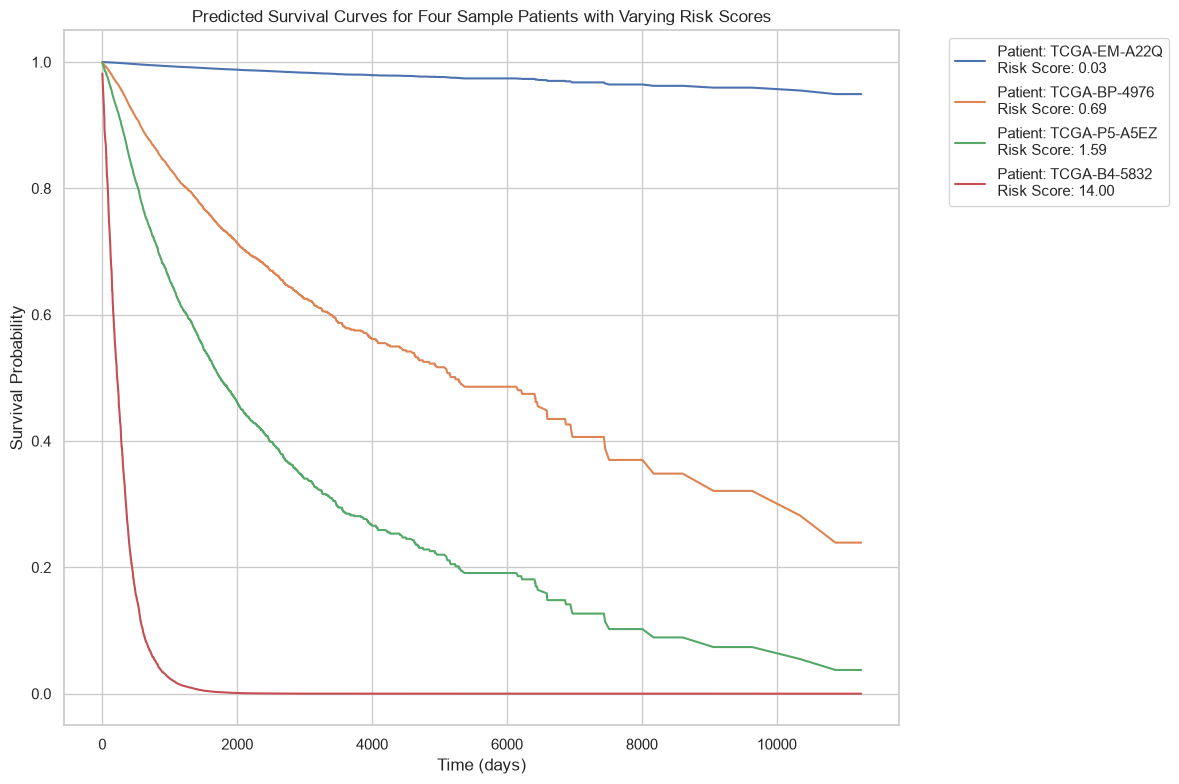

In [40]:
import matplotlib.pyplot as plt

# Sort patients by risk score to select those with different risk profiles
patient_level_merged_data_sorted = patient_level_merged_data.sort_values(by='risk_score').reset_index(drop=True)

# Select 4 patients from different quartiles of the risk score distribution
# (e.g., 25th, 50th, 75th, and 100th percentile patients)
sample_indices = [
    patient_level_merged_data_sorted.index[0], # Lowest risk
    patient_level_merged_data_sorted.index[int(len(patient_level_merged_data_sorted) * 0.25)],
    patient_level_merged_data_sorted.index[int(len(patient_level_merged_data_sorted) * 0.75)],
    patient_level_merged_data_sorted.index[-1] # Highest risk
]
sample_patients = patient_level_merged_data_sorted.loc[sample_indices]

plt.figure(figsize=(12, 8))

# Iterate through the sample patients and plot their predicted survival curves
for index, patient_row in sample_patients.iterrows():
    patient_id = patient_row['patient_id']
    risk_score = patient_row['risk_score']

    # Use the original `cph_model` to predict survival for just these patients
    single_patient_survival_curve_df = cph_model.predict_survival_function(patient_row[latent_cols].to_frame().T)

    plt.plot(single_patient_survival_curve_df.index, single_patient_survival_curve_df.iloc[:, 0],
             label=f'Patient: {patient_id}\nRisk Score: {risk_score:.2f}')

plt.title('Predicted Survival Curves for Four Sample Patients with Varying Risk Scores')
plt.xlabel('Time (days)')
plt.ylabel('Survival Probability')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

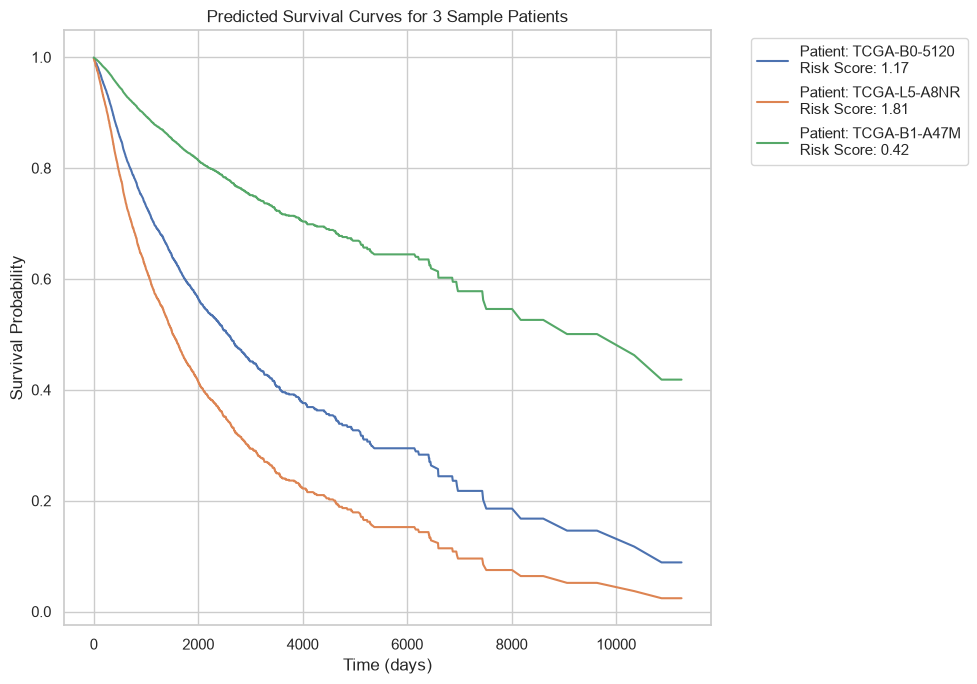

In [41]:
import matplotlib.pyplot as plt

# Select 3 random sample patients
sample_patients = patient_level_merged_data.sample(n=3, random_state=42)

plt.figure(figsize=(10, 7))

# Iterate through the sample patients and plot their predicted survival curves
for index, patient_row in sample_patients.iterrows():
    patient_id = patient_row['patient_id']
    risk_score = patient_row['risk_score']
    survival_curve = patient_row['predicted_survival_curve']

    # The predicted_survival_curve is a list of survival probabilities over time.
    # The time points are implicitly from the cph_model's fitted duration range.
    # To plot correctly, we need the time index from the original predicted_survival_curves DataFrame.

    # Find the corresponding predicted_survival_curves entry for this patient_id
    # The predicted_survival_curves DataFrame has time as index and patient_ids as columns
    # We need to find the column that matches the current patient_id.
    # The column names in predicted_survival_curves are indices of patient_level_merged_data when it was passed to predict_survival_function.

    # A more robust way: use the original `cph_model` to predict for just these patients
    single_patient_survival_curve_df = cph_model.predict_survival_function(patient_row[latent_cols].to_frame().T)

    plt.plot(single_patient_survival_curve_df.index, single_patient_survival_curve_df.iloc[:, 0],
             label=f'Patient: {patient_id}\nRisk Score: {risk_score:.2f}')

plt.title('Predicted Survival Curves for 3 Sample Patients')
plt.xlabel('Time (days)')
plt.ylabel('Survival Probability')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

In [42]:
# Calculate the average risk score for each cancer type
average_risk_by_cancer_type = patient_level_merged_data.groupby('cancer type abbreviation')['risk_score'].mean().reset_index()

# Sort the results for better readability (optional)
average_risk_by_cancer_type = average_risk_by_cancer_type.sort_values(by='risk_score', ascending=False)

print("Average Risk Score by Cancer Type:")
display(average_risk_by_cancer_type)


Average Risk Score by Cancer Type:


,cancer type abbreviation,risk_score
7,ESCA,2.901656
8,GBM,2.898867
18,MESO,2.222353
4,CHOL,2.022225
24,SARC,1.930418
9,HNSC,1.835647
15,LIHC,1.817032
17,LUSC,1.693308
13,LAML,1.639611
20,PAAD,1.625790


## Final Task

### Subtask:
Summarize the findings from the clustering and Kaplan-Meier analysis, highlighting any clusters with distinct survival outcomes based on the log-rank tests.


## Summary:

### Data Analysis Key Findings
*   **Patient-level Data Preparation:** A `patient_level_merged_data` DataFrame was successfully created, containing 10025 unique patient entries. This DataFrame integrates patient-level latent dimension embeddings (mean of 32 latent features) with corresponding survival data (OS.time, OS) and cancer type information.
*   **Clustering Results:** KMeans clustering partitioned the patients into 5 distinct clusters based on their scaled latent features. The cluster sizes varied, ranging from 1028 to 3004 patients per cluster.
*   **Survival Outcome Differences:**
    *   The Kaplan-Meier survival curves visually demonstrated varying survival probabilities across the different clusters.
    *   Log-rank tests revealed statistically significant differences in survival outcomes for most pairwise cluster comparisons (p-values often well below 0.05).
    *   Specifically, Cluster 0 consistently showed significant differences against Clusters 1, 2, and 3. Cluster 1 showed significant differences against Clusters 3 and 4, and Cluster 2 against Clusters 3 and 4. Cluster 3 showed significant differences against Cluster 4.
    *   **No Significant Difference Found:** The log-rank test between **Cluster 0 and Cluster 4** yielded a high p-value (0.9312069), indicating no statistically significant difference in survival between these two groups. Similarly, **Cluster 1 and Cluster 2** also did not show a statistically significant difference (p-value of 0.1798228) at a conventional alpha level of 0.05.

### Insights or Next Steps
*   The identification of distinct patient clusters with varying survival outcomes based on latent features suggests that these latent dimensions successfully capture clinically relevant biological heterogeneity. Further investigation into the specific biological characteristics (e.g., gene expression, mutations) differentiating these clusters could provide valuable insights into disease mechanisms and potential therapeutic targets.
*   Since Cluster 0 and Cluster 4, and Cluster 1 and Cluster 2 did not show significant differences in survival, a next step could involve re-evaluating the optimal number of clusters or exploring other clustering algorithms to potentially achieve more distinct survival profiles, or to investigate common underlying biological features within these non-differentiated pairs.
